Set `R_ohms` and `C_farads` in the simulation cell to change the RC circuit from the notebook. The cell runs ngspice and plots the resulting magnitude and phase response.

In [1]:
import sys
print(sys.executable)

/home/will/spice-agent/.venv/bin/python


In [10]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 3.3 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 8.8 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 9.3 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 8.9 MB/s  0:00:00 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


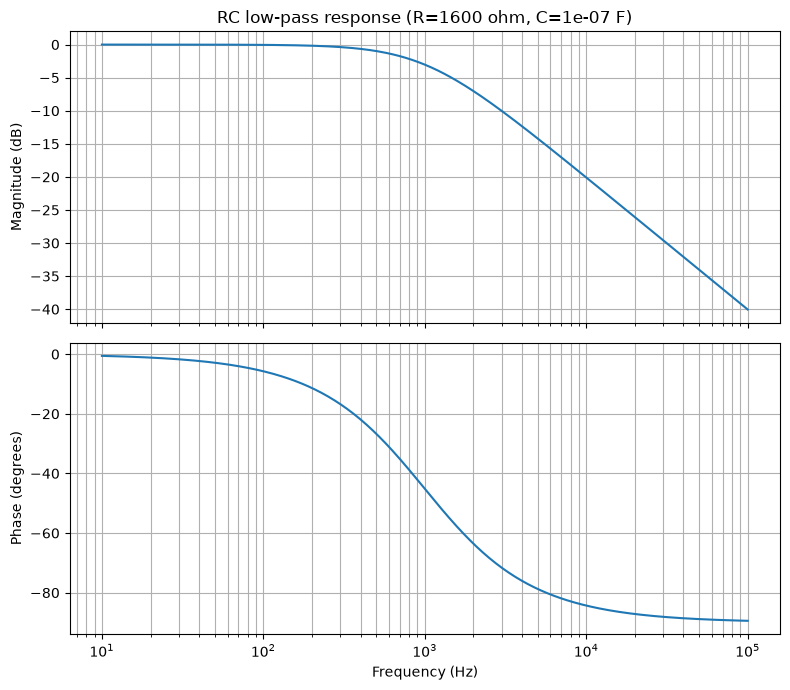

Measured cutoff: 994.72 Hz
{'fc': 994.7182}
Measured cutoff: 994.72 Hz
{'fc': 994.7182}
Theoretical cutoff: 994.72 Hz


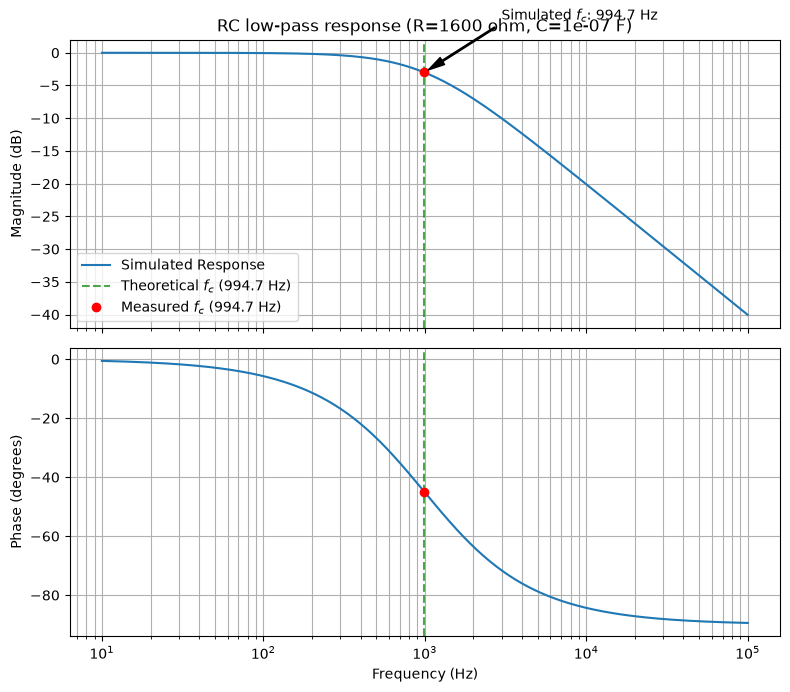

In [ ]:
import argparse
import itertools
import math
from pathlib import Path
import re
import shutil
import subprocess
import tempfile

import matplotlib.pyplot as plt
import numpy as np

# 1. Set up the CLI Command-Line Argument Parser
parser = argparse.ArgumentParser(
    description="Sweep RC low-pass filter component values using ngspice."
)
parser.add_argument(
    "-r", "--resistors",
    type=float,
    nargs="+",
    required=True,
    help="One or more resistor values in ohms (e.g., -r 1000 4700 10000)"
)
parser.add_argument(
    "-c", "--capacitors",
    type=float,
    nargs="+",
    required=True,
    help="One or more capacitor values in farads (e.g., -c 1e-6 10e-6)"
)
args = parser.parse_args()

# 2. Basic environment validations
ngspice = shutil.which("ngspice")
if ngspice is None:
    raise RuntimeError("ngspice isn't installed or isn't on PATH")

candidates = [Path("circuits/rc_lowpass.cir"), Path("rc_lowpass.cir")]
netlist = next((path for path in candidates if path.is_file()), None)
if netlist is None:
    raise FileNotFoundError(f"Couldn't find rc_lowpass.cir from {Path.cwd()}")

deck_template = netlist.read_text()

# Initialize Matplotlib subplots for plotting multiple traces
fig, (magnitude_ax, phase_ax) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# 3. Generate all combinations of R and C and iterate over them
combinations = list(itertools.product(args.resistors, args.capacitors))
print(f"Starting sweep of {len(combinations)} component combination(s)...\n")

for R_ohms, C_farads in combinations:
    if R_ohms <= 0 or C_farads <= 0 or not math.isfinite(R_ohms) or not math.isfinite(C_farads):
        print(f"Skipping invalid pair: R={R_ohms}, C={C_farads}")
        continue

    # Overwrite the parameter line dynamically inside the template loop
    parameter_line = f".param RVAL={R_ohms:.12g} CVAL={C_farads:.12g}"
    deck, replacements = re.subn(r"(?im)^\.param\s+RVAL=.*$", parameter_line, deck_template)
    if replacements != 1:
        raise RuntimeError("Expected exactly one .param RVAL=... line in the netlist")

    # Call ngspice inside a temporary directory context
    with tempfile.TemporaryDirectory() as temp_dir:
        run_netlist = Path(temp_dir) / netlist.name
        run_netlist.write_text(deck)
        
        result = subprocess.run(
            [ngspice, "-b", str(run_netlist)],
            cwd=temp_dir,
            capture_output=True,
            text=True,
            timeout=30,
        )

        error_lines = [
            (stream_name, line)
            for stream_name, output in (
                ("stdout", result.stdout),
                ("stderr", result.stderr),
            )
            for line in output.splitlines()
            if "ERROR" in line
        ]
        if error_lines:
            print(f"Error reported by ngspice for R={R_ohms}, C={C_farads}:")
            for stream_name, line in error_lines:
                print(f"  {stream_name}: {line}")
            continue

        if result.returncode != 0:
            print(f"Warning: ngspice failed for R={R_ohms}, C={C_farads}. Skipping graph line.")
            continue

        # Load the newly written data
        data_path = Path(temp_dir) / "ac_response.dat"
        if not data_path.is_file():
            continue
        data = np.loadtxt(data_path, skiprows=1)

    # Extract simulation data vectors
    frequency_hz = data[:, 0]
    gain_db = data[:, 1]
    phase_deg = np.degrees(data[:, 2]) # Converting raw SPICE radians to degrees

    # Find the measured cutoff reported via stdout
    match = re.search(
        r"^\s*fc\s*=\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)",
        result.stdout,
        re.MULTILINE | re.IGNORECASE,
    )
    fc_measured = float(match.group(1)) if match else None
    fc_theoretical = 1.0 / (2.0 * math.pi * R_ohms * C_farads)

    # Label key for our graph legend items
    run_label = f"R={R_ohms:g}Ω, C={C_farads:g}F (fc={fc_theoretical:.1f}Hz)"
    print(f"Processed: R={R_ohms:g} Ω, C={C_farads:g} F | Theoretical fc: {fc_theoretical:.2f} Hz | Simulated fc: {fc_measured}")

    # Plot lines into our shared subplots
    line, = magnitude_ax.semilogx(frequency_hz, gain_db, label=run_label)
    color = line.get_color() # Match marker dot color to trace line automatically
    
    phase_ax.semilogx(frequency_hz, phase_deg, color=color)

    # Drop interactive intersection markers for each sweep run
    if fc_measured:
        magnitude_ax.plot(fc_measured, -3.0, marker='o', color=color)
        phase_ax.plot(fc_measured, -45.0, marker='o', color=color)

# 4. Finalize the Graph Presentation and Styling
magnitude_ax.set_ylabel("Magnitude (dB)")
magnitude_ax.set_title("RC Low-Pass Filter Parameter Sweep")
magnitude_ax.grid(True, which="both")
magnitude_ax.legend(loc="lower left", bbox_to_anchor=(1.02, 0), borderaxespad=0)

phase_ax.set_xlabel("Frequency (Hz)")
phase_ax.set_ylabel("Phase (degrees)")
phase_ax.grid(True, which="both")

fig.tight_layout()
plt.show()
